# 03 — Línea base con las 561 características

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/garcialvarez/HAR/blob/main/03_linea_base_features.ipynb)

**Entrega 2 — Notebook 3 de 7.** Modelos de *machine learning clásico* sobre el vector de 561
características de dominio tiempo/frecuencia que ya trae el dataset. Sirve como **referencia** para
juzgar si las redes profundas (notebooks 04–06) realmente aportan algo.

- **Modelos:** Regresión Logística, Random Forest y SVM con kernel RBF.
- **Hiperparámetros:** `GridSearchCV` con `GroupKFold(5)` y `groups = sujeto`, para que ningún sujeto
  aparezca a la vez en entrenamiento y validación (ver notebook 02, sección 6).
- **Selección del mejor modelo:** por la accuracy de validación cruzada, **no** por la del test, para no
  filtrar información del conjunto de prueba.
- **Evaluación final:** partición oficial (21 sujetos train / 9 sujetos test), una sola vez por modelo.
- **Métricas de negocio:** latencia por ventana (un solo hilo, lote de 1), tamaño del modelo y tiempo de
  entrenamiento.

**Entradas:** dataset UCI HAR (se descarga solo). **Salidas:** métricas en este notebook y en `results/`
(carpeta local no versionada).

In [1]:
# --- Arranque (Colab o local): clona el repositorio si hace falta y entra en él ---
import os, subprocess

REPO_URL = "https://github.com/garcialvarez/HAR.git"

if not os.path.exists("src/data_loader.py"):      # en Colab: cwd = /content
    if not os.path.isdir("HAR"):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("HAR")

print("Directorio de trabajo:", os.getcwd())

Directorio de trabajo: C:\Users\GARCIA\Documents\HAR


In [2]:
# Instala las dependencias (en Colab casi todas ya vienen instaladas).
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


C:\Users\GARCIA\Documents\HAR\.venv\Scripts\python.exe: No module named pip


In [3]:
# Descarga y descomprime el UCI HAR Dataset (si no está ya en data/raw/).
import sys
sys.path.append("src")

from data_loader import download_dataset
download_dataset()

WindowsPath('C:/Users/GARCIA/Documents/HAR/data/raw/UCI_HAR_Dataset')

In [4]:
import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, GroupKFold, cross_val_score
from sklearn.svm import SVC

from data_loader import load_features
from evaluation import evaluate_and_save, measure_latency, plot_confusion_matrix
from preprocessing import CLASS_NAMES, encode_labels

pd.set_option("display.width", 130)
SEED = 42

X_tr_df, y_tr_s, s_tr = load_features("train")
X_te_df, y_te_s, s_te = load_features("test")
X_tr, X_te = X_tr_df.values, X_te_df.values
y_tr, y_te = encode_labels(y_tr_s), encode_labels(y_te_s)
s_tr = s_tr.values

assert not set(s_tr) & set(s_te.values), "train y test comparten sujetos"
cv = GroupKFold(n_splits=5)
print("train:", X_tr.shape, "| test:", X_te.shape, "| sujetos train:", len(set(s_tr)))

train: (7352, 561) | test: (2947, 561) | sujetos train: 21


## 1. Entrenamiento y selección de hiperparámetros

Las 561 features ya están en [−1, 1], así que no hace falta escalarlas.

- **Regresión Logística:** `C ∈ {0.1, 1, 10}`.
- **Random Forest:** 300 árboles (sin búsqueda; es la línea base de la Entrega 1).
- **SVM RBF:** `C ∈ {1, 10, 100}` × `gamma ∈ {scale, 0.01, 0.001}` (9 combinaciones × 5 folds).

In [5]:
resultados = {}      # nombre -> dict con modelo, cv, tiempo de entrenamiento y hiperparámetros

# --- Regresión Logística ---
gs_lr = GridSearchCV(LogisticRegression(max_iter=3000), {"C": [0.1, 1, 10]},
                     cv=cv, scoring="accuracy", n_jobs=-1)
gs_lr.fit(X_tr, y_tr, groups=s_tr)
resultados["LogReg"] = dict(model=gs_lr.best_estimator_, cv=gs_lr.best_score_,
                            fit_s=gs_lr.refit_time_, params=gs_lr.best_params_)

# --- Random Forest (sin búsqueda: CV agrupada solo para reportar su accuracy de validación) ---
rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
cv_rf = cross_val_score(rf, X_tr, y_tr, cv=cv, groups=s_tr, scoring="accuracy").mean()
t0 = time.perf_counter()
rf.fit(X_tr, y_tr)
resultados["RandomForest"] = dict(model=rf, cv=cv_rf, fit_s=time.perf_counter() - t0,
                                  params={"n_estimators": 300})

# --- SVM RBF ---
gs_svm = GridSearchCV(SVC(kernel="rbf"), {"C": [1, 10, 100], "gamma": ["scale", 0.01, 0.001]},
                      cv=cv, scoring="accuracy", n_jobs=-1)
gs_svm.fit(X_tr, y_tr, groups=s_tr)
resultados["SVM-RBF"] = dict(model=gs_svm.best_estimator_, cv=gs_svm.best_score_,
                             fit_s=gs_svm.refit_time_, params=gs_svm.best_params_)

for k, r in resultados.items():
    print(f"{k:13s} CV por sujeto = {r['cv']:.4f}   mejores hiperparámetros: {r['params']}")

LogReg        CV por sujeto = 0.9401   mejores hiperparámetros: {'C': 10}
RandomForest  CV por sujeto = 0.9173   mejores hiperparámetros: {'n_estimators': 300}
SVM-RBF       CV por sujeto = 0.9411   mejores hiperparámetros: {'C': 100, 'gamma': 0.01}


## 2. Evaluación en el test oficial

`n_params` cuenta: coeficientes (Regresión Logística), nodos totales (Random Forest) y valores de los
vectores de soporte más sus coeficientes duales (SVM). El tamaño es el del modelo serializado con `pickle`.
La latencia se mide con **un solo hilo y una ventana por llamada**, que es el escenario de un teléfono.

In [6]:
resultados["RandomForest"]["model"].set_params(n_jobs=1)     # latencia en un solo hilo (escenario on-device)


def n_parametros(nombre, m):
    if nombre == "LogReg":
        return m.coef_.size + m.intercept_.size
    if nombre == "RandomForest":
        return sum(e.tree_.node_count for e in m.estimators_)
    return m.support_vectors_.size + m.dual_coef_.size


IDS = {"LogReg": "03_logreg", "RandomForest": "03_random_forest", "SVM-RBF": "03_svm_rbf"}
metricas = {}
for nombre, r in resultados.items():
    m = r["model"]
    y_pred = m.predict(X_te)
    lat = measure_latency(m.predict, X_te)
    metricas[nombre] = evaluate_and_save(
        IDS[nombre], "clasico_561_features", y_te, y_pred, CLASS_NAMES,
        train_time_s=r["fit_s"], latency=lat, n_params=n_parametros(nombre, m),
        model_size_kb=len(pickle.dumps(m)) / 1024, notes=str(r["params"]))

tabla = pd.DataFrame({
    n: {"CV por sujeto": resultados[n]["cv"], "accuracy test": x["accuracy"], "F1 macro test": x["f1_macro"],
        "latencia (ms/ventana)": x["latency_single_ms"], "parámetros": x["n_params"],
        "tamaño (KB)": x["model_size_kb"], "entrenamiento (s)": x["train_time_s"]}
    for n, x in metricas.items()}).T
display(tabla.round(4))

[03_logreg] accuracy=0.9634  F1 macro=0.9633  latencia=0.12 ms/ventana


[03_random_forest] accuracy=0.9287  F1 macro=0.9271  latencia=16.72 ms/ventana


[03_svm_rbf] accuracy=0.9654  F1 macro=0.9649  latencia=0.39 ms/ventana


,CV por sujeto,accuracy test,F1 macro test,latencia (ms/ventana),parámetros,tamaño (KB),entrenamiento (s)
LogReg,0.9401,0.9634,0.9633,0.1216,3372.0,27.0537,2.8893
RandomForest,0.9173,0.9287,0.9271,16.7239,159286.0,17525.0137,4.7853
SVM-RBF,0.9411,0.9654,0.9649,0.3921,637316.0,4985.0068,0.6656


## 3. Mejor modelo, matriz de confusión y errores por clase

El "mejor" se elige por la **accuracy de validación cruzada por sujeto**, no por el test.

Mejor modelo por CV por sujeto: SVM-RBF  (CV = 0.9411, test = 0.9654)


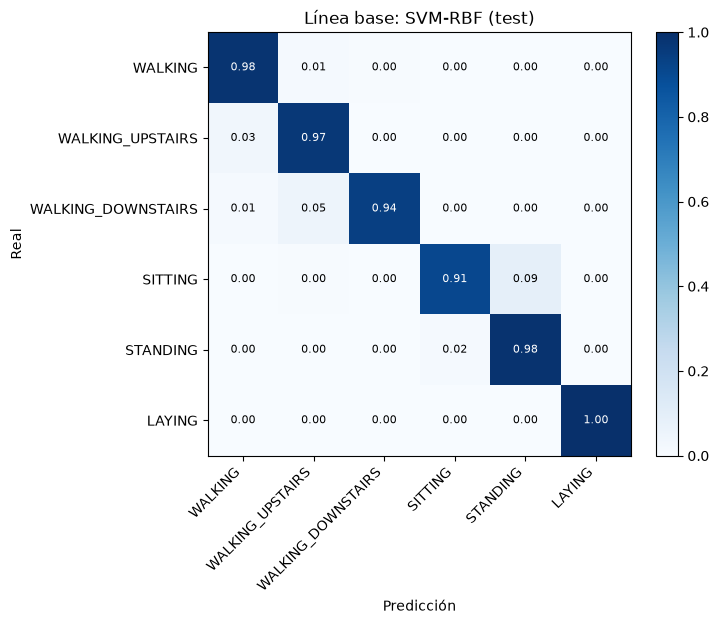

,F1,tasa de falsos negativos
WALKING,0.972,0.016
WALKING_UPSTAIRS,0.954,0.034
WALKING_DOWNSTAIRS,0.966,0.060
SITTING,0.944,0.092
STANDING,0.954,0.015
LAYING,1.000,0.000


In [7]:
mejor = max(resultados, key=lambda k: resultados[k]["cv"])
print(f"Mejor modelo por CV por sujeto: {mejor}  (CV = {resultados[mejor]['cv']:.4f}, "
      f"test = {metricas[mejor]['accuracy']:.4f})")

plot_confusion_matrix(metricas[mejor]["confusion_matrix"], CLASS_NAMES,
                      title=f"Línea base: {mejor} (test)", save_name="03_confusion_mejor.png")

por_clase = pd.DataFrame({"F1": {c: metricas[mejor]["per_class"][c]["f1-score"] for c in CLASS_NAMES},
                          "tasa de falsos negativos": metricas[mejor]["false_negative_rate"]})
display(por_clase.round(3))

## 4. Comparación con la literatura y con la Entrega 1

| Referencia | Accuracy |
|---|---|
| ELM secuencial (Chandan Kumar et al., 2016) | 93.3 % |
| CNN (Jiang & Yin, 2015) | 95.2 % |
| SVM (Anguita et al., 2013) | 96.0 % |
| DRNN unidireccional de 4 capas (Murad & Pyun, 2017) | 96.7 % |
| Random Forest — línea base de la Entrega 1 | ≈ 92.9 % |

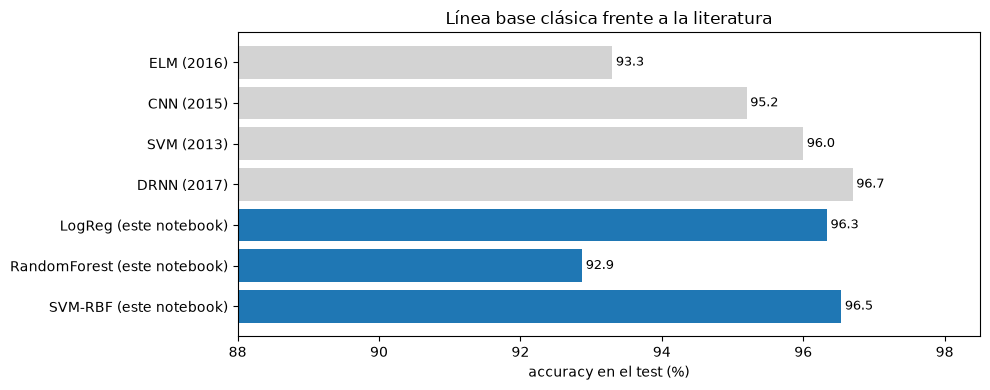

In [8]:
ref = {"ELM (2016)": 93.3, "CNN (2015)": 95.2, "SVM (2013)": 96.0, "DRNN (2017)": 96.7}
propios = {f"{n} (este notebook)": 100 * x["accuracy"] for n, x in metricas.items()}

fig, ax = plt.subplots(figsize=(10, 4))
nombres = list(ref) + list(propios)
valores = list(ref.values()) + list(propios.values())
ax.barh(nombres, valores, color=["lightgrey"] * len(ref) + ["C0"] * len(propios))
for i, v in enumerate(valores):
    ax.text(v + 0.05, i, f"{v:.1f}", va="center", fontsize=9)
ax.set_xlim(88, 98.5)
ax.set_xlabel("accuracy en el test (%)")
ax.set_title("Línea base clásica frente a la literatura")
ax.invert_yaxis()
fig.tight_layout()
plt.show()

## Conclusiones

In [9]:
s = resultados["SVM-RBF"]
print(f"- Finalista de la familia clásica para el notebook 07: SVC(kernel='rbf', {s['params']}).")
print(f"- Mejor por CV por sujeto: {mejor} (CV {resultados[mejor]['cv']:.3f}, test {metricas[mejor]['accuracy']:.3f}).")
conf = np.array(metricas[mejor]["confusion_matrix"])
i, j = CLASS_NAMES.index("SITTING"), CLASS_NAMES.index("STANDING")
print(f"- Confusión SITTING↔STANDING: {conf[i, j] + conf[j, i]} de {conf.sum()} ventanas del test; "
      "las posturas estáticas son el principal punto débil, como se anticipó en la Entrega 1.")
print(f"- Latencia del mejor modelo: {metricas[mejor]['latency_single_ms']:.3f} ms/ventana, "
      f"tamaño {metricas[mejor]['model_size_kb']:.0f} KB.")
print("- La CV por sujeto (21 sujetos) es menor que la accuracy en el test (9 sujetos): con tan pocos sujetos de prueba,")
print("  el resultado depende de quiénes caen en el test. Por eso el notebook 07 repite la CV sobre los 30 sujetos.")

- Finalista de la familia clásica para el notebook 07: SVC(kernel='rbf', {'C': 100, 'gamma': 0.01}).
- Mejor por CV por sujeto: SVM-RBF (CV 0.941, test 0.965).
- Confusión SITTING↔STANDING: 51 de 2947 ventanas del test; las posturas estáticas son el principal punto débil, como se anticipó en la Entrega 1.
- Latencia del mejor modelo: 0.392 ms/ventana, tamaño 4985 KB.
- La CV por sujeto (21 sujetos) es menor que la accuracy en el test (9 sujetos): con tan pocos sujetos de prueba,
  el resultado depende de quiénes caen en el test. Por eso el notebook 07 repite la CV sobre los 30 sujetos.


Siguiente: [`04_cnn1d_dominio_tiempo.ipynb`](04_cnn1d_dominio_tiempo.ipynb) — redes convolucionales 1D
sobre la señal cruda (familia A: dominio del tiempo).